# 04 · Logistic Regression

The linear model. L2-regularised logistic regression on the shared 122-feature input; the inverse regularisation strength `C` is tuned on a log scale.

**Protocol (identical for every model; `src/controlled_framework.py`, `config.yaml`):**
- **Novelty-aware tuning.** Optuna TPE, the same number of trials for every model. The objective is the mean ROC-AUC over 5 *leave-attack-types-out* folds of `KDDTrain+`: each fold holds out a group of training attack types plus 1/5 of the normal rows, so the score measures how well held-out attack types are separated from normal traffic. The preprocessor is refit inside every fold.
- **Fixed parameters.** `class_weight=None` (or its equivalent) for every model; `random_state` = the run's seed.
- **Final refit.** On all of `KDDTrain+` with the **full** best-trial parameter set (tuned + fixed); `cf.check_final_params` asserts it.
- **Single evaluation on `KDDTest+`**, reported four ways:
  - at the fixed threshold 0.5;
  - threshold-free (ROC-AUC, PR-AUC, AUC of seen attacks vs normals, AUC of unseen attacks vs normals);
  - at FPR budgets of 1/2/5% read off the test ROC curve (ranking quality at a matched FPR);
  - at *deployable* thresholds, chosen so that 1/2/5% of the out-of-fold `KDDTrain+` normals exceed them. These use training data only, so the realised test FPR can differ from the budget.
- **Seeds.** The whole pipeline (tuning + refit + evaluation) runs once per seed in `config.yaml`. The primary seed (42) writes the model and the headline files; the other seeds write to `results/*/seeds/`.

**Outputs:** `models/logistic_regression.joblib`, `results/metrics/logistic_regression.json`, `results/predictions/logistic_regression_predictions.csv`, `results/predictions/logistic_regression_oof_train_scores.csv`, `results/tuning/logistic_regression_trials.{json,csv}`, `results/*/seeds/logistic_regression_seed*.*`, `results/tables/logistic_regression_*.{csv,md}`, `results/figures/logistic_regression/*.png`.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


## 1. Search space and fixed parameters

In [2]:
MODEL_NAME = "Logistic Regression"
FIXED = {"solver": "lbfgs", "max_iter": 2000, "class_weight": cf.CLASS_WEIGHT, "random_state": cf.SEED}
FOLD_JOBS = 5   # CV folds run in parallel for single-threaded estimators

def suggest(trial):
    return {"C": trial.suggest_float("C", 1e-3, 1e2, log=True)}

from sklearn.linear_model import LogisticRegression

def factory(params):
    return LogisticRegression(**params)

def complexity(pipe, preds):
    clf = pipe.named_steps["clf"]
    assert clf.n_iter_[0] < clf.max_iter, "lbfgs did not converge"
    return {"C": float(clf.C), "coef_l2_norm": float(np.linalg.norm(clf.coef_)),
            "n_nonzero_coef": int((np.abs(clf.coef_) > 1e-8).sum()), "n_iter": int(clf.n_iter_[0])}

print("fixed:", FIXED)

fixed: {'solver': 'lbfgs', 'max_iter': 2000, 'class_weight': None, 'random_state': 42}


## 2. Primary seed: tune (novelty CV), refit on `KDDTrain+`, evaluate once on `KDDTest+`

In [3]:
data = cf.load_dataset()
res = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=cf.SEED, data=data, fold_jobs=FOLD_JOBS)
res.metrics["model_complexity"] = complexity(res.pipeline, res.predictions)
print()
print("best novelty CV AUC:", round(res.best_cv_auc, 4), "| fold AUCs:", np.round(res.best_cv_fold_aucs, 4))
print("final model parameters:", res.best_params)
print("model complexity:", res.metrics["model_complexity"])

  [Logistic Regression | seed 42] trial 01/25  novelty CV AUC 0.8878 (±0.1317)


  [Logistic Regression | seed 42] trial 02/25  novelty CV AUC 0.8792 (±0.1289)


  [Logistic Regression | seed 42] trial 03/25  novelty CV AUC 0.8800 (±0.1285)


  [Logistic Regression | seed 42] trial 04/25  novelty CV AUC 0.8828 (±0.1297)


  [Logistic Regression | seed 42] trial 05/25  novelty CV AUC 0.9043 (±0.1011)


  [Logistic Regression | seed 42] trial 06/25  novelty CV AUC 0.9042 (±0.1011)


... (16 outputs left out)

  [Logistic Regression | seed 42] trial 23/25  novelty CV AUC 0.9063 (±0.0930)


  [Logistic Regression | seed 42] trial 24/25  novelty CV AUC 0.8946 (±0.1198)


  [Logistic Regression | seed 42] trial 25/25  novelty CV AUC 0.9062 (±0.0923)



best novelty CV AUC: 0.9063 | fold AUCs: [0.9744 0.8867 0.9811 0.7327 0.9565]
final model parameters: {'solver': 'lbfgs', 'max_iter': 2000, 'class_weight': None, 'random_state': 42, 'C': 0.002364959235671184}
model complexity: {'C': 0.002364959235671184, 'coef_l2_norm': 3.4406961132957825, 'n_nonzero_coef': 121, 'n_iter': 27}


## 3. Tuning results

The cell also reports how far apart the best trials are relative to the fold-to-fold standard deviation. A spread smaller than one fold SD means this objective does not clearly separate the top configurations.

top-5 spread = 0.00064  vs  best-trial fold SD = 0.09302


,trial,mean_auc,std_auc,duration_seconds,solver,max_iter,class_weight,random_state,C
0,22,0.906277,0.093022,4.91,lbfgs,2000,None,42,0.002365
1,21,0.906244,0.092181,4.44,lbfgs,2000,None,42,0.002148
2,24,0.906185,0.092324,3.67,lbfgs,2000,None,42,0.002183
3,6,0.905949,0.091086,4.18,lbfgs,2000,None,42,0.001952
4,17,0.905636,0.096145,5.06,lbfgs,2000,None,42,0.003075
5,10,0.904965,0.089217,4.15,lbfgs,2000,None,42,0.001408
6,15,0.904841,0.099335,3.81,lbfgs,2000,None,42,0.004552
7,20,0.904501,0.100011,5.39,lbfgs,2000,None,42,0.005108
8,4,0.904268,0.101132,6.10,lbfgs,2000,None,42,0.006027
9,5,0.904240,0.101118,5.19,lbfgs,2000,None,42,0.006025


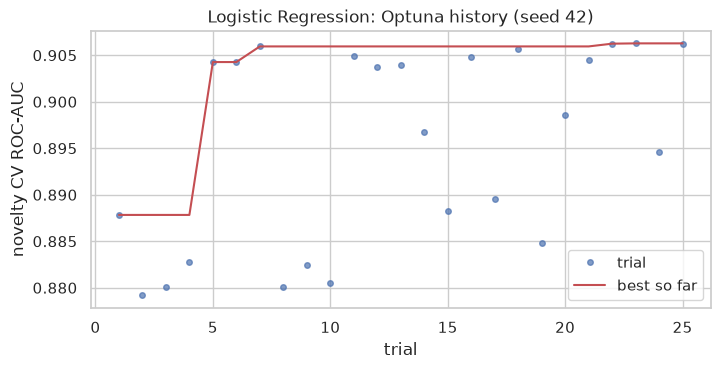

In [4]:
tt = cf.trials_table(res)
spread = tt["mean_auc"].iloc[0] - tt["mean_auc"].iloc[min(4, len(tt) - 1)]
print(f"top-5 spread = {spread:.5f}  vs  best-trial fold SD = {np.std(res.best_cv_fold_aucs):.5f}")
display(tt.head(10))

fig, ax = plt.subplots(figsize=(8, 3.6))
vals = [t["mean_auc"] for t in res.trials]
ax.plot(range(1, len(vals) + 1), vals, "o", ms=4, alpha=.7, label="trial")
ax.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), "-", color="#C44E52", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("novelty CV ROC-AUC"); ax.set_title(f"{MODEL_NAME}: Optuna history (seed {cf.SEED})"); ax.legend()
cf.save_figure(fig, "logistic_regression", "tuning_history"); plt.show()

## 4. Test results (`KDDTest+`)

In [5]:
m = res.metrics
display(pd.Series(cf.summary_row(m)).to_frame(MODEL_NAME))
ops = pd.concat({"test ROC reading (matched test FPR)": pd.DataFrame(m["test_roc_operating_points"]).T,
                 "deployable (OOF-calibrated threshold)": pd.DataFrame(m["deployable_operating_points"]).T}).reset_index(names=["kind", "budget"])
cat = pd.DataFrame(m["attack_category_recall"]).T.reset_index(names="category")
strat = pd.DataFrame([{"category": c, "seen_n": v["seen"]["total_samples"], "seen_recall": v["seen"]["recall"],
                       "unseen_n": v["unseen"]["total_samples"], "unseen_recall": v["unseen"]["recall"]}
                      for c, v in m["category_stratified_seen_unseen_recall"].items()])
unseen = pd.DataFrame(m["per_unseen_attack_recall"]).T.reset_index(names="attack").sort_values("total_samples", ascending=False)
cf.save_table(ops, "logistic_regression_operating_points")
cf.save_table(cat, "logistic_regression_category_recall")
cf.save_table(strat, "logistic_regression_category_stratified")
cf.save_table(unseen, "logistic_regression_per_unseen_attack")
display(ops); display(strat); display(unseen)

,Logistic Regression
model,Logistic Regression
accuracy,0.736858
macro_f1,0.735835
attack_precision,0.915373
attack_recall,0.592535
false_positive_rate,0.0724
seen_recall,0.7152
unseen_recall,0.2955
generalization_drop_pp,41.97
reweighted_drop_pp,47.72


,kind,budget,threshold,fpr,attack_recall,seen_recall,unseen_recall
0,test ROC reading (matched test FPR),fpr_1pct,0.947819,0.009990,0.425544,0.579654,0.052267
1,test ROC reading (matched test FPR),fpr_2pct,0.939710,0.019979,0.435440,0.592976,0.053867
2,test ROC reading (matched test FPR),fpr_5pct,0.905196,0.049949,0.471908,0.637014,0.072000
3,deployable (OOF-calibrated threshold),fpr_1pct,0.643994,0.066838,0.553651,0.695255,0.210667
4,deployable (OOF-calibrated threshold),fpr_2pct,0.510067,0.071885,0.588717,0.713090,0.287467
5,deployable (OOF-calibrated threshold),fpr_5pct,0.287939,0.080433,0.660017,0.753936,0.432533


,category,seen_n,seen_recall,unseen_n,unseen_recall
0,DoS,5741,0.9342,1717,0.1800
1,Probe,1106,0.9647,1315,0.5992
2,R2L,2199,0.0259,688,0.0102
3,U2R,37,0.2432,30,0.1333


,attack,category,total_samples,detected,missed,recall
3,mscan,Probe,996,485,511,0.4869
0,apache2,DoS,737,141,596,0.1913
5,processtable,DoS,685,168,517,0.2453
10,snmpguess,R2L,331,3,328,0.0091
7,saint,Probe,319,303,16,0.9498
2,mailbomb,DoS,293,0,293,0.0
9,snmpgetattack,R2L,178,0,178,0.0
1,httptunnel,R2L,133,0,133,0.0
4,named,R2L,17,2,15,0.1176
6,ps,U2R,15,0,15,0.0


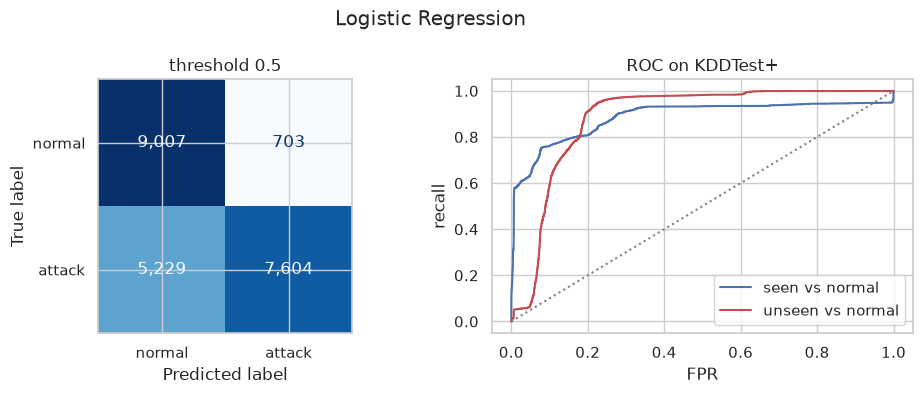

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(np.array(m["overall_metrics"]["confusion_matrix"]), display_labels=["normal", "attack"]).plot(
    ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("threshold 0.5")
p = res.predictions
for name, mask, col in [("seen vs normal", (p.y_true == 0) | ~p.is_unseen, "#4C72B0"), ("unseen vs normal", (p.y_true == 0) | p.is_unseen, "#C44E52")]:
    fpr, tpr, _ = roc_curve(p.y_true[mask], p.y_prob[mask]); axes[1].plot(fpr, tpr, color=col, label=name)
axes[1].plot([0, 1], [0, 1], ":", color="grey"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("recall"); axes[1].legend()
axes[1].set_title("ROC on KDDTest+")
fig.suptitle(MODEL_NAME); fig.tight_layout()
cf.save_figure(fig, "logistic_regression", "confusion_and_roc"); plt.show()

## 5. Save primary-seed artifacts

In [7]:
paths = cf.save_experiment(res, primary=True)
for k, v in paths.items():
    print(f"{k:12s} {v.relative_to(PROJECT_ROOT)}")

metrics      results/metrics/logistic_regression.json
predictions  results/predictions/logistic_regression_predictions.csv
tuning_json  results/tuning/logistic_regression_trials.json
tuning_csv   results/tuning/logistic_regression_trials.csv
model        models/logistic_regression.joblib
oof          results/predictions/logistic_regression_oof_train_scores.csv


## 6. Remaining seeds (full pipeline per seed)

In [8]:
seed_rows = [cf.summary_row(res.metrics) | {"seed": cf.SEED, "best_novelty_cv_auc": res.best_cv_auc}]
for s in [s for s in cf.SEEDS if s != cf.SEED]:
    r = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=s, data=data, fold_jobs=FOLD_JOBS, verbose=False)
    r.metrics["model_complexity"] = complexity(r.pipeline, r.predictions)
    cf.save_experiment(r, primary=False)
    seed_rows.append(cf.summary_row(r.metrics) | {"seed": s, "best_novelty_cv_auc": r.best_cv_auc})
    print(f"seed {s}: CV AUC {r.best_cv_auc:.4f} | test unseen AUC {r.metrics['threshold_free']['roc_auc_unseen_vs_normal']:.4f} | "
          f"unseen recall@0.5 {r.metrics['seen_vs_unseen_recall']['unseen_recall']:.4f} | params { {k: v for k, v in r.best_params.items() if k not in FIXED} }")
    del r
seeds_tbl = pd.DataFrame(seed_rows)
cols = ["seed", "best_novelty_cv_auc", "macro_f1", "false_positive_rate", "seen_recall", "unseen_recall",
        "auc_seen_vs_normal", "auc_unseen_vs_normal", "unseen_recall@test_fpr_2pct", "test_fpr@oof_fpr_2pct", "unseen_recall@oof_fpr_2pct"]
seeds_tbl = seeds_tbl[cols]
cf.save_table(seeds_tbl, "logistic_regression_seeds")
display(seeds_tbl)
display(seeds_tbl.drop(columns="seed").agg(["mean", "std"]).T)

seed 1: CV AUC 0.9056 | test unseen AUC 0.8831 | unseen recall@0.5 0.2973 | params {'C': 0.0022906508718265385}


seed 2: CV AUC 0.9052 | test unseen AUC 0.8831 | unseen recall@0.5 0.2957 | params {'C': 0.002382431289300328}


seed 3: CV AUC 0.9053 | test unseen AUC 0.8832 | unseen recall@0.5 0.2936 | params {'C': 0.0025007886182339865}


seed 4: CV AUC 0.9043 | test unseen AUC 0.8831 | unseen recall@0.5 0.2997 | params {'C': 0.002067378892308403}


,seed,best_novelty_cv_auc,macro_f1,false_positive_rate,seen_recall,unseen_recall,auc_seen_vs_normal,auc_unseen_vs_normal,unseen_recall@test_fpr_2pct,test_fpr@oof_fpr_2pct,unseen_recall@oof_fpr_2pct
0,42,0.906277,0.735835,0.072400,0.7152,0.2955,0.885431,0.883139,0.053867,0.071885,0.287467
1,1,0.905611,0.736062,0.072297,0.7149,0.2973,0.885787,0.883078,0.053867,0.072091,0.292000
2,2,0.905195,0.735881,0.072400,0.7152,0.2957,0.885363,0.883141,0.053867,0.071988,0.287467
3,3,0.905347,0.735421,0.072400,0.7150,0.2936,0.884796,0.883228,0.053600,0.072400,0.291200
4,4,0.904350,0.736476,0.072297,0.7149,0.2997,0.887139,0.883063,0.054400,0.071782,0.293067


,mean,std
best_novelty_cv_auc,0.905356,0.000699
macro_f1,0.735935,0.000383
false_positive_rate,0.072359,0.000056
seen_recall,0.715040,0.000152
unseen_recall,0.296360,0.002282
auc_seen_vs_normal,0.885703,0.000878
auc_unseen_vs_normal,0.883130,0.000065
unseen_recall@test_fpr_2pct,0.053920,0.000292
test_fpr@oof_fpr_2pct,0.072029,0.000237
unseen_recall@oof_fpr_2pct,0.290240,0.002617


**Reading these numbers.** Seed-to-seed spread shows how much of any difference between models comes from training and tuning randomness rather than from the model family. The cross-model comparison is in `08_evaluation_comparison.ipynb`.